# 2. Model results
The training code is in `src/train.py`. This notebook runs it and draws the results.

In [1]:
# ---- setup: libraries, our own code (src/), and a helper to save charts
import sys
sys.path.insert(0, "..")            # lets the notebook find the src/ folder
import warnings
warnings.filterwarnings("ignore")

import json
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from src import prep, train, stats

CHARTS_FOLDER = prep.PROJECT_FOLDER / "outputs" / "figures"

def save_chart(name):
    """Save the current chart as a PNG in outputs/figures and show it."""
    plt.savefig(CHARTS_FOLDER / (name + ".png"), dpi=150, bbox_inches="tight")
    plt.show()

def light_style():
    """White background (used for charts 01-14)."""
    mpl.rcdefaults()
    sns.set_theme(style="whitegrid")

def dark_style():
    """Dark background matching the app (used for charts 15-25)."""
    mpl.rcParams.update({"figure.facecolor": "#0e1117", "axes.facecolor": "#0e1117",
                         "savefig.facecolor": "#0e1117", "text.color": "#e8eaed",
                         "axes.labelcolor": "#e8eaed", "axes.titlecolor": "#e8eaed",
                         "xtick.color": "#e8eaed", "ytick.color": "#e8eaed",
                         "axes.edgecolor": "#3a4050", "grid.color": "#3a4050",
                         "legend.labelcolor": "#e8eaed"})

## Baseline — Logistic Regression vs Random Forest
Both give extra weight to defaults (`class_weight="balanced"`), because only 18% of loans default.

In [2]:
results, baseline = train.baseline()
print(json.dumps(results["results"], indent=2))

{
  "Logistic Regression": {
    "roc_auc": 0.7376,
    "pr_auc": 0.3663
  },
  "Random Forest": {
    "roc_auc": 0.8421,
    "pr_auc": 0.5892
  }
}


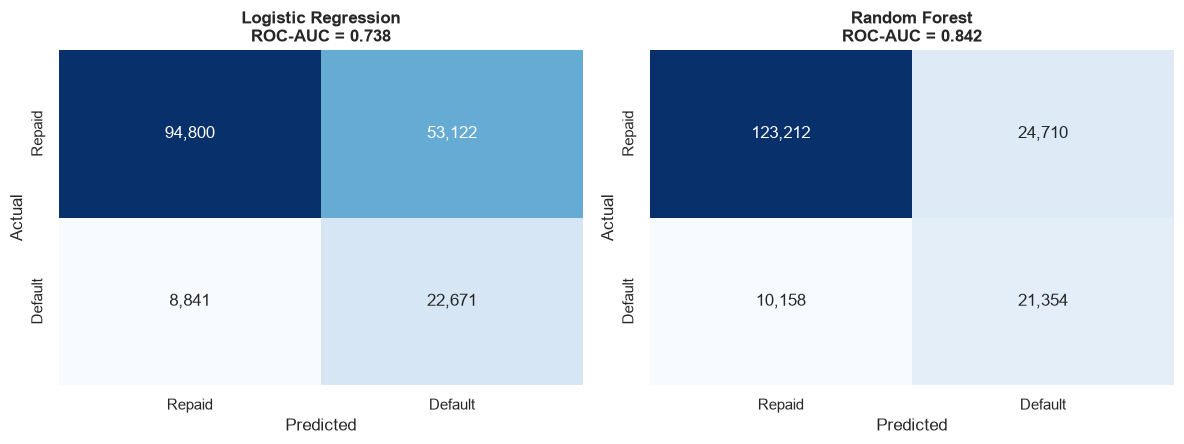

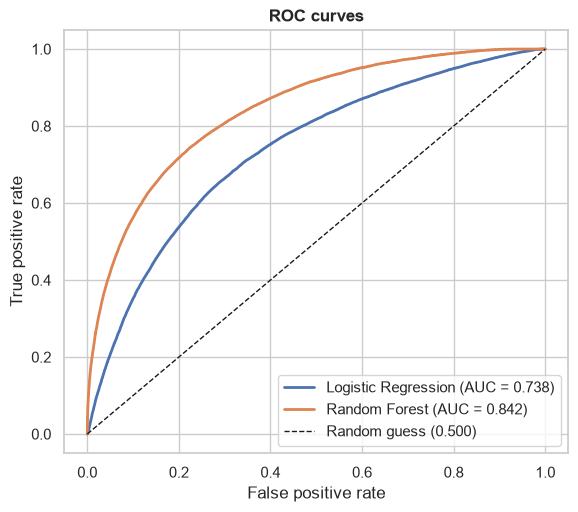

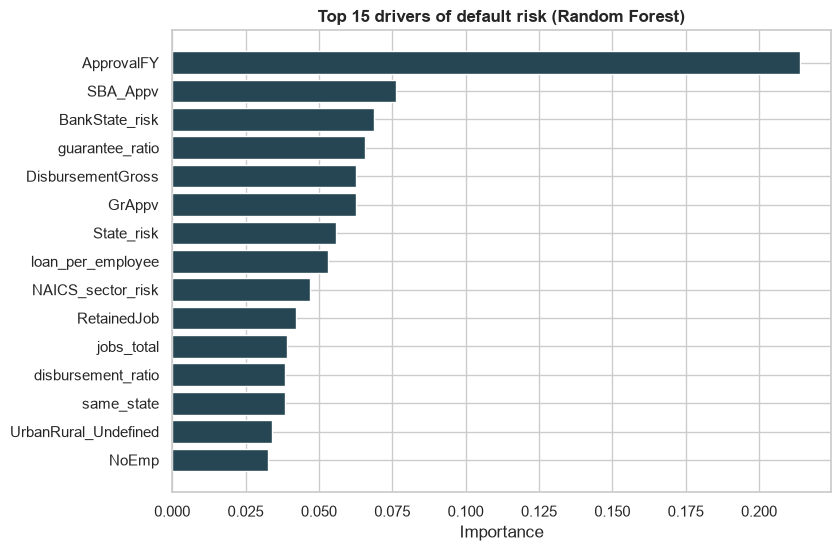

In [3]:
from sklearn.metrics import confusion_matrix, roc_curve
light_style()

X_test = baseline["X_test"]
y_test = baseline["y_test"]
logistic_probability = baseline["logistic"].predict_proba(baseline["scaler"].transform(X_test))[:, 1]
forest_probability = baseline["forest"].predict_proba(X_test)[:, 1]
models = [("Logistic Regression", logistic_probability), ("Random Forest", forest_probability)]

# ---- confusion matrices (a loan counts as "default" if its probability is 0.5 or more)
figure, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for axis, (name, probability) in zip(axes, models):
    matrix = confusion_matrix(y_test, probability >= 0.5)
    sns.heatmap(matrix, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=axis,
                xticklabels=["Repaid", "Default"], yticklabels=["Repaid", "Default"])
    score = results["results"][name]["roc_auc"]
    axis.set_title(name + "\nROC-AUC = " + str(round(score, 3)), fontweight="bold")
    axis.set_xlabel("Predicted")
    axis.set_ylabel("Actual")
plt.tight_layout()
save_chart("05_confusion_matrices")

# ---- ROC curves
figure, axis = plt.subplots(figsize=(6.5, 5.5))
for name, probability in models:
    false_positive_rate, true_positive_rate, _ = roc_curve(y_test, probability)
    score = results["results"][name]["roc_auc"]
    axis.plot(false_positive_rate, true_positive_rate, lw=2, label=name + " (AUC = " + str(round(score, 3)) + ")")
axis.plot([0, 1], [0, 1], "k--", lw=1, label="Random guess (0.500)")
axis.set_xlabel("False positive rate")
axis.set_ylabel("True positive rate")
axis.legend(loc="lower right")
axis.set_title("ROC curves", fontweight="bold")
save_chart("06_roc_curves")

# ---- the forest's own feature importance (top 15)
importance = pd.Series(baseline["forest"].feature_importances_, index=X_test.columns)
importance = importance.sort_values(ascending=False).head(15)
figure, axis = plt.subplots(figsize=(8.5, 6))
axis.barh(importance.index, importance.values, color="#264653")
axis.invert_yaxis()
axis.set_xlabel("Importance")
axis.set_title("Top 15 drivers of default risk (Random Forest)", fontweight="bold")
save_chart("07_feature_importance")

## Calibration — are the probabilities honest?
Giving defaults extra weight makes the model over-state risk. Calibration, fitted on loans the
forest never saw (and with the forest frozen), fixes the numbers without changing the ranking.

chosen_method : Isotonic
roc_auc_before : 0.84011751606144
roc_auc_after : 0.8400677867795462
ece_before : 0.16945616015801745
ece_after : 0.0019859216364085074
ece_sigmoid : 0.01223570404445266
brier_before : 0.14179231937293726
brier_after : 0.10458458990754306


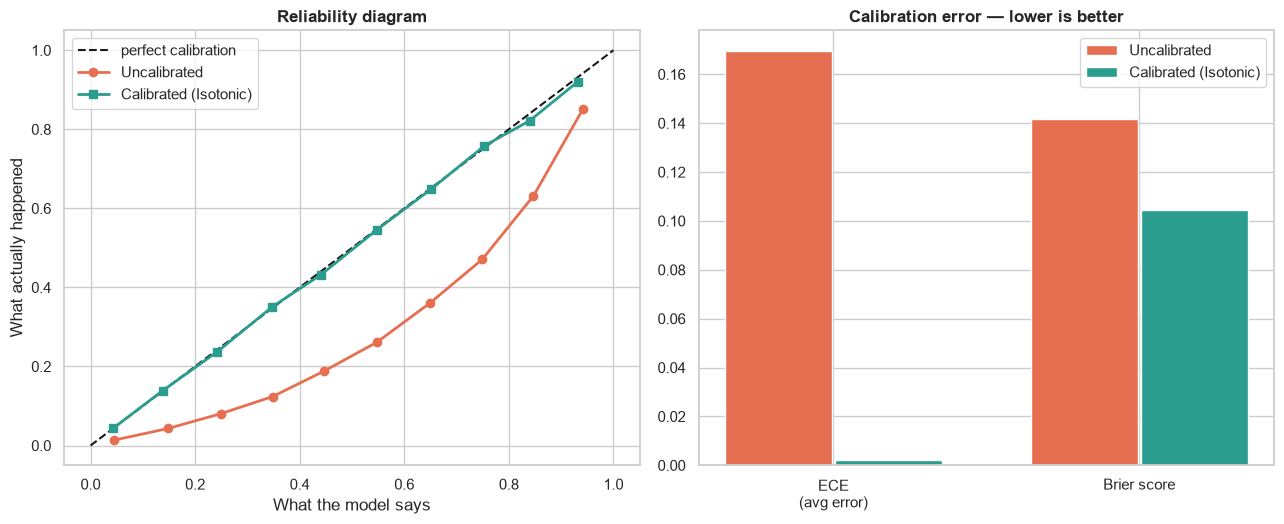

In [4]:
calibration_results, calibration = train.calibration()
for key, value in calibration_results.items():
    print(key, ":", value)

def predicted_vs_actual(probability):
    """Average prediction and real default rate in 10 groups (0-10%, 10-20%, ...)."""
    table = pd.DataFrame({"predicted": probability, "actual": np.asarray(calibration["y_test"])})
    table["group"] = pd.cut(probability, np.linspace(0, 1, 11), include_lowest=True)
    return table.groupby("group", observed=True)[["predicted", "actual"]].mean()

figure, axes = plt.subplots(1, 2, figsize=(13, 5.4))

# ---- left: reliability diagram (on the diagonal = honest)
axes[0].plot([0, 1], [0, 1], "k--", lw=1.5, label="perfect calibration")
before = predicted_vs_actual(calibration["before"])
after = predicted_vs_actual(calibration["after"])
axes[0].plot(before["predicted"], before["actual"], marker="o", lw=2, color="#e76f51", label="Uncalibrated")
axes[0].plot(after["predicted"], after["actual"], marker="s", lw=2, color="#2a9d8f", label="Calibrated (Isotonic)")
axes[0].set_xlabel("What the model says")
axes[0].set_ylabel("What actually happened")
axes[0].set_title("Reliability diagram", fontweight="bold")
axes[0].legend(loc="upper left")

# ---- right: the error before and after
positions = np.arange(2)
axes[1].bar(positions - 0.18, [calibration_results["ece_before"], calibration_results["brier_before"]], 0.35,
            label="Uncalibrated", color="#e76f51")
axes[1].bar(positions + 0.18, [calibration_results["ece_after"], calibration_results["brier_after"]], 0.35,
            label="Calibrated (Isotonic)", color="#2a9d8f")
axes[1].set_xticks(positions)
axes[1].set_xticklabels(["ECE\n(avg error)", "Brier score"])
axes[1].legend()
axes[1].set_title("Calibration error — lower is better", fontweight="bold")
plt.tight_layout()
save_chart("08_calibration")

## The app's model — what does it rely on most?
**SHAP** measures how much each fact pushes a loan's risk up or down. Averaged over 2,000 test
loans, it shows which facts the model relies on most. (The app uses the same idea to show the
"Main reasons" for each loan.)

{'roc_auc': 0.8370926974787103, 'recall': 0.7338474232038589, 'precision': 0.41100881558367697, 'ece': 0.0023802037379229814}


ApprovalFY              22.3
same_state               9.7
UrbanRural_Undefined     7.4
guarantee_ratio          7.0
BankState_risk           6.8
SBA_Appv                 6.3
GrAppv                   5.1
NAICS_sector_risk        5.1
dtype: float64


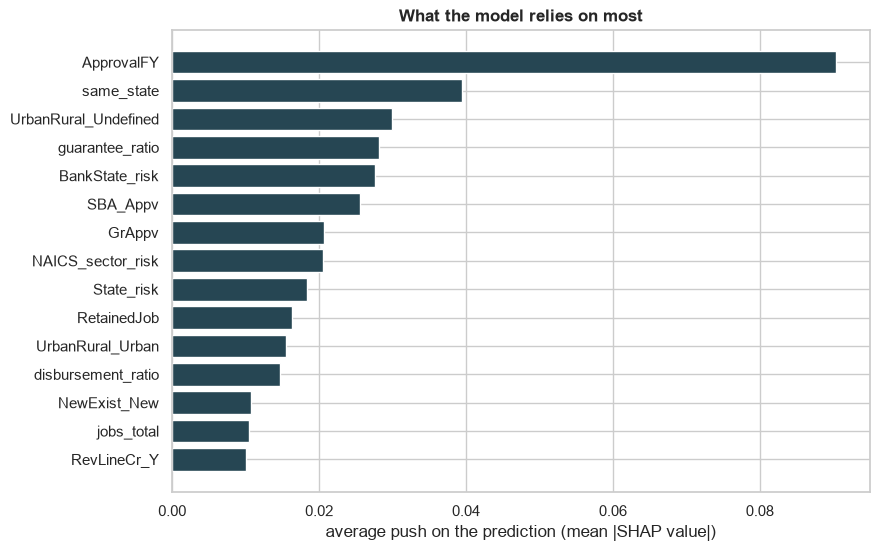

In [5]:
import shap
app_metrics, app = train.app_model()
print(app_metrics)

# explain 2,000 random test loans
generator = np.random.default_rng(train.RANDOM_SEED)
chosen_rows = generator.choice(len(app["X_test"]), 2000, replace=False)
X_explain = app["X_test"].iloc[chosen_rows]
explainer = shap.TreeExplainer(app["forest"])
shap_values = np.array(explainer.shap_values(X_explain, check_additivity=False))[:, :, 1]

# average size of each column's push = how much the model relies on it
importance = pd.Series(np.abs(shap_values).mean(axis=0), index=X_explain.columns)
importance = importance.sort_values(ascending=False)
importance.head(15).to_json(prep.PROJECT_FOLDER / "outputs" / "shap_importance.json", indent=2)
print((importance / importance.sum() * 100).round(1).head(8))

top_15 = importance.head(15).sort_values()
figure, axis = plt.subplots(figsize=(9, 6))
axis.barh(top_15.index, top_15.values, color="#264653")
axis.set_xlabel("average push on the prediction (mean |SHAP value|)")
axis.set_title("What the model relies on most", fontweight="bold")
save_chart("09_shap_global_importance")

## Risk levels — does each level mean what it says?
Lower < 10% · Medium 10–35% · Higher > 35%, checked on 179,434 test loans.

        share  predicted  actual
level                           
LOW      50.0        4.3     4.3
MEDIUM   34.0       19.0    18.9
HIGH     16.0       56.4    56.1


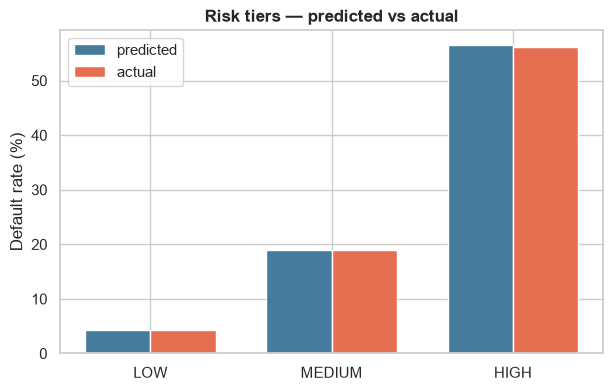

In [6]:
probability = app["calibrated"].predict_proba(app["X_test"])[:, 1]
level = pd.cut(probability, [0, 0.10, 0.35, 1.01], labels=["LOW", "MEDIUM", "HIGH"], right=False)
table = pd.DataFrame({"level": level, "predicted": probability, "actual": app["y_test"].values})

summary = table.groupby("level", observed=True).agg(share=("actual", "size"),
                                                    predicted=("predicted", "mean"),
                                                    actual=("actual", "mean"))
summary["share"] = summary["share"] / summary["share"].sum()
print((summary * 100).round(1))

figure, axis = plt.subplots(figsize=(7, 4.2))
positions = np.arange(3)
axis.bar(positions - 0.18, summary["predicted"] * 100, 0.36, label="predicted", color="#457b9d")
axis.bar(positions + 0.18, summary["actual"] * 100, 0.36, label="actual", color="#e76f51")
axis.set_xticks(positions)
axis.set_xticklabels(summary.index)
axis.set_ylabel("Default rate (%)")
axis.legend()
axis.set_title("Risk tiers — predicted vs actual", fontweight="bold")
save_chart("13_risk_tiers")